<a href="https://colab.research.google.com/github/Spacegaeguri/Drowsiness-Detection-System/blob/main/Drowsiness_Detection_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
!kaggle datasets download -d ismailnasri20/driver-drowsiness-dataset-ddd

!unzip -q driver-drowsiness-dataset-ddd.zip -d dataset/

import os
print("데이터셋 준비 완료! 내부 폴더:", os.listdir('dataset'))

Dataset URL: https://www.kaggle.com/datasets/ismailnasri20/driver-drowsiness-dataset-ddd
License(s): unknown
driver-drowsiness-dataset-ddd.zip: Skipping, found more recently modified local copy (use --force to force download)
replace dataset/Driver Drowsiness Dataset (DDD)/Drowsy/A0001.png? [y]es, [n]o, [A]ll, [N]one, [r]ename: 데이터셋 준비 완료! 내부 폴더: ['Driver Drowsiness Dataset (DDD)']


In [8]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
import matplotlib.pyplot as plt

# 얼굴 전체를 인식해야 하므로 사이즈 키움
IMG_HEIGHT = 128
IMG_WIDTH = 128
BATCH_SIZE = 32
EPOCHS = 15

# 데이터셋 폴더 구조에 맞춰 경로 수정
TRAIN_DIR = 'dataset/Driver Drowsiness Dataset (DDD)'

In [9]:
# 다양한 주행 환경을 시뮬레이션하기 위한 증강 세팅
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,           # 고개가 기울어지는 상황 대비
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
    zoom_range=0.1,
    brightness_range=[0.7, 1.3], # 터널, 야간, 주간 빛 변화 대비
    validation_split=0.2
)

# 컬러 이미지(rgb)로 학습
train_generator = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    subset='training',
    color_mode='rgb'             # 색상 정보 포함
)

validation_generator = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    subset='validation',
    color_mode='rgb'
)

# 모델이 어떤 번호를 매겼는지 확인
print("\n클래스 매핑 결과:", train_generator.class_indices)

Found 3019 images belonging to 2 classes.
Found 753 images belonging to 2 classes.

클래스 매핑 결과: {'Drowsy': 0, 'Non Drowsy': 1}


In [10]:
gitignore_content = """dataset/
*.h5
*.pt
runs/
__pycache__/
.DS_Store
"""

with open('.gitignore', 'w') as f:
    f.write(gitignore_content)

print('.gitignore 파일이 최상단에 생성되었습니다.')
!cat .gitignore

.gitignore 파일이 최상단에 생성되었습니다.
dataset/
*.h5
*.pt
runs/
__pycache__/
.DS_Store


In [15]:
# from tensorflow.keras.layers import Input
# from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# model = Sequential([
#     # 기존 Conv2D에 있던 input_shape를 지우고, 대신 맨 위에 Input 레이어를 따로 추가해!
#     Input(shape=(IMG_HEIGHT, IMG_WIDTH, 3)),
#     Conv2D(32, (3, 3), activation='relu'),
#     MaxPooling2D((2, 2)),

#     Conv2D(64, (3, 3), activation='relu'),
#     MaxPooling2D((2, 2)),

#     Conv2D(128, (3, 3), activation='relu'),
#     MaxPooling2D((2, 2)),

#     Flatten(),
#     Dense(128, activation='relu'),
#     Dropout(0.5),
#     Dense(1, activation='sigmoid')
# ])

from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# 1. 구글의 사전 학습된 MobileNetV2 모델 불러오기 (머리(top) 부분은 제외)
base_model = MobileNetV2(
    input_shape=(IMG_HEIGHT, IMG_WIDTH, 3),
    include_top=False,
    weights='imagenet' # 수백만 장의 이미지로 학습된 지능을 그대로 가져옴
)

# 2. 가져온 모델의 기존 가중치는 얼려두기 (우리의 적은 데이터로 망가지는 것을 방지)
base_model.trainable = False

# 3. 졸음 감지에 맞게 새로운 머리(분류기) 달아주기
model = Sequential([
    base_model,
    GlobalAveragePooling2D(),
    Dense(128, activation='relu'),
    Dropout(0.5), # 과적합 방지
    Dense(1, activation='sigmoid') # 0(졸음) 또는 1(각성) 출력
])

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model.summary()

# model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
# model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,081 (9.24 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [16]:
print("얼굴 기반 졸음 감지 학습을 시작합니다!")
# 1. 조기 종료 조건 설정 (3번 동안 개선 없으면 종료)
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True,
    verbose=1
)

# 2. 최적 모델 자동 저장 조건 설정
model_checkpoint = ModelCheckpoint(
    'best_drowsiness_model.h5', # 앞으로 저장될 파일 이름
    monitor='val_loss',
    save_best_only=True,
    verbose=1
)

# 3. 학습 진행 (callbacks 옵션 추가)
history = model.fit(
    train_generator,
    epochs=EPOCHS,
    validation_data=validation_generator,
    callbacks=[early_stopping, model_checkpoint] # 방금 만든 조건 투입!
)

print("학습 완료 및 최적 모델 저장 완료!")

얼굴 기반 졸음 감지 학습을 시작합니다!
Epoch 1/15
95/95 ━━━━━━━━━━━━━━━━━━━━ 0s 558ms/step - accuracy: 0.6612 - loss: 0.6338
Epoch 1: val_loss improved from None to 0.90329, saving model to best_drowsiness_model.h5



Epoch 1: finished saving model to best_drowsiness_model.h5
95/95 ━━━━━━━━━━━━━━━━━━━━ 75s 729ms/step - accuracy: 0.7423 - loss: 0.5126 - val_accuracy: 0.5989 - val_loss: 0.9033
Epoch 2/15
95/95 ━━━━━━━━━━━━━━━━━━━━ 0s 563ms/step - accuracy: 0.8793 - loss: 0.3071
Epoch 2: val_loss did not improve from 0.90329
95/95 ━━━━━━━━━━━━━━━━━━━━ 67s 704ms/step - accuracy: 0.8827 - loss: 0.2901 - val_accuracy: 0.5697 - val_loss: 0.9652
Epoch 3/15
95/95 ━━━━━━━━━━━━━━━━━━━━ 0s 564ms/step - accuracy: 0.9172 - loss: 0.2210
Epoch 3: val_loss did not improve from 0.90329
95/95 ━━━━━━━━━━━━━━━━━━━━ 67s 705ms/step - accuracy: 0.9218 - loss: 0.2125 - val_accuracy: 0.6308 - val_loss: 1.0419
Epoch 4/15
95/95 ━━━━━━━━━━━━━━━━━━━━ 0s 561ms/step - accuracy: 0.9401 - loss: 0.1732
Epoch 4: val_loss did not improve from 0.90329
95/95 ━━━━━━━━━━━━━━━━━━━━ 74s 779ms/step - accuracy: 0.9453 - loss: 0.1618 - val_accuracy: 0.6109 - val_loss: 1.0756
Epoch 4: early stopping
Restoring model weights from the end of the b


테스트할 얼굴 사진(눈을 감거나 뜬 사진)을 업로드해주세요.


Saving images11.jpg to images11 (1).jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 44033 (\N{HANGUL SYLLABLE GAG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 49457 (\N{HANGUL SYLLABLE SEONG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 49345 (\N{HANGUL SYLLABLE SANG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 53468 (\N{HANGUL SYLLABLE TAE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


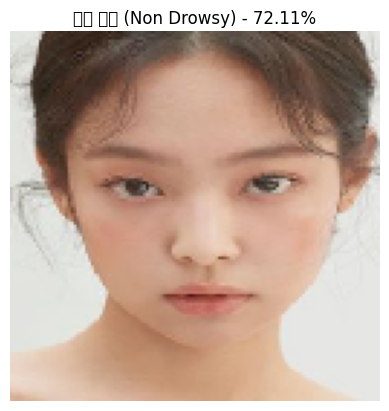

최종 예측: 각성 상태 (Non Drowsy) - 72.11%


In [17]:
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
from tensorflow.keras.preprocessing import image
from tensorflow.keras.models import load_model
import os

# 설정값 정의
IMG_HEIGHT = 128
IMG_WIDTH = 128
MODEL_PATH = 'best_drowsiness_model.h5'

# 모델이 메모리에 없으면 파일에서 로드
if 'model' not in globals():
    if os.path.exists(MODEL_PATH):
        print(f"저장된 모델({MODEL_PATH})을 불러옵니다...")
        model = load_model(MODEL_PATH)
    else:
        print("에러: 학습된 모델 파일이 없습니다. 학습 셀을 먼저 완료해주세요.")

if 'model' in globals():
    print('\n테스트할 얼굴 사진(눈을 감거나 뜬 사진)을 업로드해주세요.')
    uploaded = files.upload()

    for fn in uploaded.keys():
        img = image.load_img(fn, target_size=(IMG_HEIGHT, IMG_WIDTH), color_mode='rgb')
        x = image.img_to_array(img)
        x = x / 255.0
        x = np.expand_dims(x, axis=0)

        prediction = model.predict(x)

        plt.imshow(img)
        plt.axis('off')

        # 클래스 매핑: {'Drowsy': 0, 'Non Drowsy': 1}
        if prediction[0] > 0.5:
            result = f"각성 상태 (Non Drowsy) - {(prediction[0][0])*100:.2f}%"
        else:
            result = f"졸음 상태 (Drowsy) - {(1-prediction[0][0])*100:.2f}%"

        plt.title(result)
        plt.show()
        print(f"최종 예측: {result}")

In [ ]:
# 1. 깃허브 사용자 정보 설정
USER_NAME = "너의_깃허브_이름"
USER_EMAIL = "너의_이름@email.com"
REPO_URL = "https://github.com/너의_계정/레포지토리_이름.git"

!git config --global user.name "{USER_NAME}"
!git config --global user.id "{USER_EMAIL}"

# 2. 레포지토리 가져오기 (이미 폴더가 있다면 이 단계는 건너뛰어도 돼)
!git clone {REPO_URL}
%cd 레포지토리_이름

In [ ]:
import shutil
import os

# 저장된 베스트 모델 파일을 깃 폴더로 복사
shutil.copy('/content/best_drowsiness_model.h5', './best_drowsiness_model.h5')

# 현재 작업 중인 코랩 파일도 저장하고 싶다면 (수동 다운로드 후 업로드 권장)
print("모델 파일이 레포지토리 폴더로 복사되었습니다.")

In [ ]:
# 1. 변경된 파일 스테이징
!git add best_drowsiness_model.h5 Drowsiness_Detection.ipynb

# 2. 커밋 메시지 작성
!git commit -m "Update: MobileNetV2 기반 고정확도 졸음 감지 모델 업데이트"

# 3. 푸시 (토큰을 입력해야 할 수도 있어)
!git push origin main